# 05 · Analyse des erreurs et pistes abandonnées

Ce qu'on a cherché une fois le modèle en place, et ce qui n'a rien donné :

1. **Résidus** : y a-t-il des groupes que le modèle surestime ou sous-estime ?
2. **Autres modèles** : LightGBM et un réseau de neurones complètent-ils CatBoost ?
3. **Mélanges** entre toutes nos expériences.
4. **Pseudo-étiquettes** : les 45 000 lignes de test peuvent-elles servir à l'entraînement ?
5. **Variabilité** : que vaut un petit écart de score ?

Les cinq notebooks : 01 données → 02 variables → 03 choix des modèles → 04 modèle final → 05 analyse des erreurs. Les CSV sont dans `data/`, les résultats dans `artifacts/<nom du notebook>/`.

In [1]:
# Environnement, chemins et fonctions partagés par les cinq notebooks
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib
import importlib.metadata
import json
import os
import platform
import shutil
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False


def find_project_dir():
    candidates = []
    if os.environ.get('HMDA_PROJECT_DIR'):
        candidates.append(Path(os.environ['HMDA_PROJECT_DIR']))
    here = Path.cwd().resolve()
    candidates += [here, *here.parents]
    candidates.append(Path('/content/drive/MyDrive/Colab Notebooks/demandes-de-pret-immobilier-aux-etats-unis'))
    for candidate in candidates:
        if (candidate / 'data' / 'train.csv').is_file() and (candidate / 'data' / 'test.csv').is_file():
            return candidate.expanduser().resolve()
    raise FileNotFoundError('Projet introuvable (data/train.csv et data/test.csv requis) ; définir HMDA_PROJECT_DIR')


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / 'data'                                        # CSV sources (lecture seule)
ARTIFACTS = PROJECT_DIR / 'artifacts'                                  # Résultats dans un sous-dossier par notebook
PREPARED_DIR = ARTIFACTS / '01_data_exploration'                       # 01 : données préparées et schéma fixe
FEATURE_DIR = ARTIFACTS / '02_feature_engineering' / 'feature_store'   # 02 : feature store
SEED = 42
CATBOOST_VERSION = '1.2.10'
GPU_NAME = None
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})


def ensure_catboost():
    """Installe et importe la version fixée de CatBoost pour le réentraînement."""
    global catboost
    try:
        installed = importlib.metadata.version('catboost')
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != CATBOOST_VERSION:
        if 'catboost' in sys.modules:
            raise RuntimeError('Une autre version de CatBoost est déjà chargée ; redémarrer puis relancer le notebook')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', f'catboost=={CATBOOST_VERSION}'])
        importlib.invalidate_caches()
    import catboost as catboost_module
    if catboost_module.__version__ != CATBOOST_VERSION:
        raise RuntimeError(f'CatBoost {CATBOOST_VERSION} requis ; version chargée : {catboost_module.__version__}')
    catboost = catboost_module
    return catboost_module


def ensure_gpu():
    """Vérifie la présence du GPU NVIDIA avant le réentraînement."""
    global GPU_NAME
    if shutil.which('nvidia-smi') is None:
        raise RuntimeError('GPU requis : choisir un GPU T4 dans le type de session Colab, puis relancer')
    probe = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                           text=True, capture_output=True, check=False)
    if probe.returncode != 0 or not probe.stdout.strip():
        raise RuntimeError('GPU NVIDIA indisponible : choisir un T4 puis relancer')
    GPU_NAME = probe.stdout.strip().splitlines()[0]
    return GPU_NAME


print('Projet :', PROJECT_DIR.name)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')

Projet : demandes-de-pret-immobilier-aux-etats-unis
Python 3.13.5 | pandas 2.2.3 | numpy 2.1.3


In [2]:
"""Identifiants de stockage historiques et libellés descriptifs.

Les valeurs assurent la reprise exacte des artefacts existants. Les paramètres,
les features et leur ordre sont définis dans les cellules métier.
Cette cellule est intégrée à chaque notebook : aucun import local requis.
"""

MODEL_DEPTH6_INITIAL = 'M0_C11_all'
MODEL_DEPTH6_ENRICHED = 'M1_C11_G7'
MODEL_DEPTH8_ENRICHED = 'M2_C7_G7'
MODEL_DEPTH6_REDUCED = 'M3_C11_lean'
FEATURE_SET_INITIAL = 'ROUND1_ALL'
FEATURE_SET_ENRICHED = 'G7'
FEATURE_SET_REDUCED = 'LEAN'
ENSEMBLE_THREE_MODELS_SEED42 = 'B13_seed42'
ENSEMBLE_MULTISEED = 'B_seeds'
ENSEMBLE_MULTISEED_PREFIX = 'B_seeds_'
ENSEMBLE_FULL_MULTISEED = 'full_Bseeds'
MODEL_INITIAL_POOL_LABEL = 'M0'
LEARNING_CURVE_SUBSET = 'LC_sub80'
LEARNING_CURVE_FULL = 'LC_full'
REDUCED_MODEL_CV_AUC = 'M3_in_13'
BASELINE_CATBOOST_DEPTH6 = 'CatBoost_R1'
BASELINE_CATBOOST_DEPTH8 = 'CatBoost_R2'
LIGHTGBM_LEAVES31 = 'L1_lgbm_leaves31'
LIGHTGBM_LEAVES127 = 'L2_lgbm_leaves127'
OBSERVED_LABELS_ONLY = 'A_base'
SOFT_PSEUDO_LABELS = 'A_pseudo'
LEARNING_CURVE_RUN_PATTERN = 'LC_*__fold?.json'
LEARNING_CURVE_FULL_PATTERN = 'LC_full__fold?.json'
REDUCED_MODEL_RUN_PATTERN = 'M3_C11_lean__fold?.json'
LIGHTGBM_RUN_PATTERN = 'L*_lgbm_*__fold?.json'
PSEUDO_LABEL_RUN_PATTERN = 'A_*__fold?.json'
FULL_ENSEMBLE_SUBMISSION = 'submission_full_Bseeds.csv'
ABLATION_ORIGINAL = 'F0_base'
ABLATION_ADD_DTI = 'F1_dti'
ABLATION_ADD_LTV = 'F2_ltv'
ABLATION_ADD_INCOME = 'F3_income'
ABLATION_ADD_MISSINGNESS = 'F4_missing'
ABLATION_ADD_GEOGRAPHIC_COUNTS = 'F5_freq'
ABLATION_INITIAL = 'F6_all'
ABLATION_INITIAL_REFERENCE = 'G0_all'
ABLATION_ADD_LTV_PRECISION = 'G1_precision'
ABLATION_ADD_LTV_THRESHOLDS = 'G2_thresholds'
ABLATION_ADD_IMPLIED_VALUE = 'G3_implied'
ABLATION_ADD_TERM = 'G4_term'
ABLATION_ENRICHED_WITH_COUNTS = 'G5_round2_all'
ABLATION_CORE_WITHOUT_COUNTS = 'G6_nofreq'
ABLATION_ENRICHED = 'G7_nofreq_round2_all'
ABLATION_ENRICHED_REFERENCE = 'H0_G7'
ABLATION_ADD_PRODUCT_FLAGS = 'H1_purpose'
ABLATION_ADD_LTV_CONSISTENCY = 'H2_ltv_consistency'
ABLATION_ADD_RISK_INTERACTIONS = 'H3_risk_layers'
ABLATION_ADD_TRACT_INCOME = 'H4_tract_income'
ABLATION_ALL_PRODUCT_RISK = 'H5_round3_all'
TUNING_DEPTH8_FIXED1600 = 'B0_R2_fixed1600'
TUNING_DEPTH8_LR005_L2_3 = 'C1_d8_lr05_l2_3_es'
TUNING_DEPTH6_LR003_L2_10 = 'C6_d6_lr03_l2_10'
TUNING_DEPTH8_LR003_L2_10 = 'C3_d8_lr03_l2_10'
TUNING_DEPTH8_LR003_L2_3 = 'C2_d8_lr03_l2_3'
TUNING_DEPTH8_LR003_L2_30 = 'C4_d8_lr03_l2_30'
TUNING_DEPTH8_BERNOULLI80 = 'C7_d8_lr03_l2_10_sub80'
TUNING_DEPTH8_WITH_DTI = 'C8_d8_lr03_l2_10_DTI'
TUNING_DEPTH10_LR003_L2_10 = 'C5_d10_lr03_l2_10'
TUNING_DEPTH8_LR002_L2_10 = 'C9_d8_lr02_l2_10'
TUNING_DEPTH8_L2_30_BERNOULLI80 = 'C10_d8_lr03_l2_30_sub80'
TUNING_DEPTH6_BERNOULLI80 = 'C11_d6_lr03_l2_10_sub80'
TRAINING_STANDARD = 'V0_base'
TRAINING_ORDERED = 'V1_ordered'
TRAINING_NEWTON_SCORE = 'V2_newtonL2'
TRAINING_DEPTHWISE = 'V3_depthwise'
TRAINING_LOSSGUIDE = 'V4_lossguide'
TRAINING_POISSON = 'V5_poisson'
TRAINING_ROWS066 = 'V6_sub066'
TRAINING_BINS254 = 'V7_border254'
TRAINING_NO_CATEGORY_COMBINATIONS = 'V8_ctr1'
TRAINING_DROP_REDUNDANT_DEMOGRAPHICS = 'V9_drop_demo'
MEAN_GAIN_VS_SOURCE_FEATURES = 'mean_delta_vs_F0'
FOLDS_BETTER_THAN_SOURCE_FEATURES = 'folds_better_than_F0'
MEAN_GAIN_VS_INITIAL_FEATURES = 'mean_delta_vs_G0'
FOLDS_BETTER_THAN_INITIAL_FEATURES = 'folds_better_than_G0'
MEAN_GAIN_VS_ENRICHED_FEATURES = 'mean_delta_vs_H0'
FOLDS_BETTER_THAN_ENRICHED_FEATURES = 'folds_better_than_H0'
MEAN_GAIN_VS_FIXED_ITERATIONS = 'mean_delta_vs_B0'
FOLDS_BETTER_THAN_FIXED_ITERATIONS = 'folds_better_than_B0'
MEAN_GAIN_VS_STANDARD_BOOSTING = 'mean_delta_vs_V0'
FOLDS_BETTER_THAN_STANDARD_BOOSTING = 'folds_better_than_V0'
GAIN_VS_THREE_MODEL_ENSEMBLE = 'delta_vs_B13'
FOLDS_BETTER_THAN_THREE_MODEL_ENSEMBLE = 'folds_better_than_B13'
TABM_ENSEMBLE_SUBMISSION_PREFIX = 'submission_Bseeds_TabM_w'
PURPOSE_ABLATION = 'feature block ablation, fast GPU CatBoost, paired vs F0_base'
PURPOSE_TRAINING_MODES = 'data-efficiency screen on M3 features; inner 15% early stop, score probe model on outer fold'
PURPOSE_TABM = 'TabM-mini (PyTorch) on G7 features; inner 15% early stop, no outer refit'
PURPOSE_FULL_REFIT = 'learning curve (80% vs 100% of outer-train) + full-data refit of M1-M3 x 3 seeds'

DISPLAY_LABELS = {
    MODEL_DEPTH6_INITIAL: 'CatBoost profondeur 6 · variables initiales',
    MODEL_DEPTH6_ENRICHED: 'CatBoost profondeur 6 · variables enrichies',
    MODEL_DEPTH8_ENRICHED: 'CatBoost profondeur 8 · variables enrichies',
    MODEL_DEPTH6_REDUCED: 'CatBoost profondeur 6 · variables réduites',
    FEATURE_SET_INITIAL: 'Variables initiales (68 colonnes)',
    FEATURE_SET_ENRICHED: 'Variables enrichies (72 colonnes)',
    FEATURE_SET_REDUCED: 'Variables réduites (68 colonnes)',
    ENSEMBLE_THREE_MODELS_SEED42: 'Ensemble de trois modèles · graine 42',
    ENSEMBLE_MULTISEED: 'Ensemble de trois modèles et trois graines',
    ENSEMBLE_MULTISEED_PREFIX: 'Ensemble multigraines · ',
    ENSEMBLE_FULL_MULTISEED: 'Ensemble multigraines sur toutes les données',
    MODEL_INITIAL_POOL_LABEL: 'CatBoost profondeur 6 · variables initiales',
    LEARNING_CURVE_SUBSET: 'Apprentissage sur 67 200 lignes',
    LEARNING_CURVE_FULL: 'Apprentissage sur 84 000 lignes',
    REDUCED_MODEL_CV_AUC: 'AUC du modèle réduit en validation croisée',
    BASELINE_CATBOOST_DEPTH6: 'CatBoost profondeur 6',
    BASELINE_CATBOOST_DEPTH8: 'CatBoost profondeur 8',
    LIGHTGBM_LEAVES31: 'LightGBM · 31 feuilles',
    LIGHTGBM_LEAVES127: 'LightGBM · 127 feuilles',
    OBSERVED_LABELS_ONLY: 'Cibles observées uniquement',
    SOFT_PSEUDO_LABELS: 'Pseudo-étiquettes souples',
    LEARNING_CURVE_RUN_PATTERN: 'Courbe d’apprentissage',
    LEARNING_CURVE_FULL_PATTERN: 'Courbe sur 84 000 lignes',
    REDUCED_MODEL_RUN_PATTERN: 'Validation croisée du modèle réduit',
    LIGHTGBM_RUN_PATTERN: 'Modèles LightGBM',
    PSEUDO_LABEL_RUN_PATTERN: 'Comparaison des pseudo-étiquettes',
    FULL_ENSEMBLE_SUBMISSION: 'Soumission de l’ensemble complet',
    ABLATION_ORIGINAL: 'Variables sources',
    ABLATION_ADD_DTI: 'Ajout des bornes DTI',
    ABLATION_ADD_LTV: 'Ajout de la cohérence LTV',
    ABLATION_ADD_INCOME: 'Ajout des ratios de revenu',
    ABLATION_ADD_MISSINGNESS: 'Ajout des valeurs manquantes',
    ABLATION_ADD_GEOGRAPHIC_COUNTS: 'Ajout des fréquences géographiques',
    ABLATION_INITIAL: 'Toutes les variables initiales',
    ABLATION_INITIAL_REFERENCE: 'Référence : variables initiales',
    ABLATION_ADD_LTV_PRECISION: 'Ajout de la précision LTV',
    ABLATION_ADD_LTV_THRESHOLDS: 'Ajout des seuils LTV',
    ABLATION_ADD_IMPLIED_VALUE: 'Ajout de la valeur immobilière implicite',
    ABLATION_ADD_TERM: 'Ajout des variables de durée',
    ABLATION_ENRICHED_WITH_COUNTS: 'Variables enrichies avec fréquences géographiques',
    ABLATION_CORE_WITHOUT_COUNTS: 'Variables initiales sans fréquences géographiques',
    ABLATION_ENRICHED: 'Variables enrichies sans fréquences géographiques',
    ABLATION_ENRICHED_REFERENCE: 'Référence : variables enrichies',
    ABLATION_ADD_PRODUCT_FLAGS: 'Ajout des indicateurs de produit',
    ABLATION_ADD_LTV_CONSISTENCY: 'Ajout de la cohérence des intervalles LTV',
    ABLATION_ADD_RISK_INTERACTIONS: 'Ajout des interactions de risque',
    ABLATION_ADD_TRACT_INCOME: 'Ajout du revenu relatif au secteur',
    ABLATION_ALL_PRODUCT_RISK: 'Ajout de tous les blocs produit et risque',
    TUNING_DEPTH8_FIXED1600: 'Profondeur 8 · 1 600 itérations fixes',
    TUNING_DEPTH8_LR005_L2_3: 'Profondeur 8 · taux 0.05 · L2=3',
    TUNING_DEPTH6_LR003_L2_10: 'Profondeur 6 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR003_L2_10: 'Profondeur 8 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR003_L2_3: 'Profondeur 8 · taux 0.03 · L2=3',
    TUNING_DEPTH8_LR003_L2_30: 'Profondeur 8 · taux 0.03 · L2=30',
    TUNING_DEPTH8_BERNOULLI80: 'Profondeur 8 · taux 0.03 · L2=10 · Bernoulli 0.8',
    TUNING_DEPTH8_WITH_DTI: 'Profondeur 8 · taux 0.03 · L2=10 · bornes DTI',
    TUNING_DEPTH10_LR003_L2_10: 'Profondeur 10 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR002_L2_10: 'Profondeur 8 · taux 0.02 · L2=10',
    TUNING_DEPTH8_L2_30_BERNOULLI80: 'Profondeur 8 · taux 0.03 · L2=30 · Bernoulli 0.8',
    TUNING_DEPTH6_BERNOULLI80: 'Profondeur 6 · taux 0.03 · L2=10 · Bernoulli 0.8',
    TRAINING_STANDARD: 'Boosting standard',
    TRAINING_ORDERED: 'Boosting ordonné',
    TRAINING_NEWTON_SCORE: 'Score NewtonL2',
    TRAINING_DEPTHWISE: 'Croissance par profondeur',
    TRAINING_LOSSGUIDE: 'Croissance guidée par la perte',
    TRAINING_POISSON: 'Échantillonnage Poisson',
    TRAINING_ROWS066: 'Échantillonnage des lignes à 0.66',
    TRAINING_BINS254: '254 seuils numériques',
    TRAINING_NO_CATEGORY_COMBINATIONS: 'Sans combinaison de catégories',
    TRAINING_DROP_REDUNDANT_DEMOGRAPHICS: 'Sans colonnes démographiques redondantes',
    MEAN_GAIN_VS_SOURCE_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_SOURCE_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_INITIAL_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_INITIAL_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_ENRICHED_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_ENRICHED_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_FIXED_ITERATIONS: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_FIXED_ITERATIONS: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_STANDARD_BOOSTING: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_STANDARD_BOOSTING: 'Plis meilleurs que la référence',
    GAIN_VS_THREE_MODEL_ENSEMBLE: 'Gain face à l’ensemble de trois modèles',
    FOLDS_BETTER_THAN_THREE_MODEL_ENSEMBLE: 'Plis meilleurs que l’ensemble de trois modèles',
    TABM_ENSEMBLE_SUBMISSION_PREFIX: 'submission_Bseeds_TabM_w',
}

def semantic_label(value):
    """Décrit un identifiant historique pour l’affichage uniquement."""
    if not isinstance(value, str):
        return value
    # Un chemin affiché doit continuer à désigner le fichier réellement présent.
    if value.endswith(('.csv', '.json', '.parquet', '.npy')):
        return value
    if value in DISPLAY_LABELS:
        return DISPLAY_LABELS[value]
    for stored in sorted(DISPLAY_LABELS, key=len, reverse=True):
        value = value.replace(stored, DISPLAY_LABELS[stored])
    return value


def display_named(value, *args, **kwargs):
    """Affiche une copie : index, colonnes et libellés lisibles, calculs inchangés."""
    if isinstance(value, (pd.DataFrame, pd.Series)):
        value = value.copy(deep=True)
        if not isinstance(value.index, pd.MultiIndex):
            value.index = value.index.map(semantic_label)
        if isinstance(value, pd.DataFrame):
            value.columns = value.columns.map(semantic_label)
            for column in value.select_dtypes(include=['object', 'string']).columns:
                value[column] = value[column].map(semantic_label)
        elif value.dtype == object:
            value = value.map(semantic_label)
    display(value, *args, **kwargs)

**Entraînement.** Tous les boutons de `TRAIN` sont à `False` : les notebooks relisent les résultats sauvegardés dans `artifacts/`. Deux exceptions : le notebook 01 entraîne un petit modèle de contrôle sur CPU et le notebook 02 réécrit les variables. Pour refaire une expérience, mettre son bouton à `True` et choisir un **GPU T4** si le bloc le demande. Les modèles déjà entraînés sont sauvegardés et ne sont pas refaits.

In [3]:
TRAIN = {
    'lightgbm': False,       # LightGBM, cinq folds (CPU, environ 30 min)
    'tabm': False,           # TabM-mini (GPU, environ 5 min pour le fold 1)
    'pseudo_label': False,   # Pseudo-labels par fold (GPU, environ 2 h ; étape complète si validation favorable)
}

## 0. Chargement des données et des variables

In [4]:
def require(condition, message):
    if not bool(condition):
        raise ValueError(message)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


manifest_path = PREPARED_DIR / 'manifest.json'
schema_path = PREPARED_DIR / 'schema.json'
if not manifest_path.is_file() or not schema_path.is_file():
    raise FileNotFoundError(
        f'Fichier manquant : {manifest_path} ou {schema_path} ; exécuter d’abord 01_data_exploration.ipynb'
    )
manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
schema = json.loads(schema_path.read_text(encoding='utf-8'))
require(manifest['schema_version'] == schema['schema_version'] == '1.0', 'Version du contrat de données incompatible')
require(manifest['seed'] == SEED and manifest['n_splits'] == 5, 'Configuration des cinq folds incompatible')
require(set(manifest['source_files']) == {'train.csv', 'test.csv', 'sample_submission.csv'},
        'Liste des fichiers source incomplète')
expected_prepared = {
    'train_features.csv', 'test_features.csv', 'train_labels.csv',
    'test_ids.csv', 'folds.csv', 'audit.csv', 'schema.json',
}
require(set(manifest['output_files']) == expected_prepared, 'Liste des fichiers préparés incomplète')
for name, info in manifest['source_files'].items():
    path = DATA_DIR / name
    require(path.is_file(), f'Données source manquantes : {path}')
    require(sha256_file(path) == info['sha256'], f'Fichier source modifié : {name} ; réexécuter 01')
for name, info in manifest['output_files'].items():
    path = PREPARED_DIR / name
    require(path.is_file(), f'Fichier préparé manquant : {path}')
    require(sha256_file(path) == info['sha256'], f'Empreinte du fichier préparé différente : {name} ; réexécuter 01')

FEATURE_COLUMNS = schema['feature_columns']
NUMERIC_COLUMNS = schema['numeric_columns']
CATEGORICAL_COLUMNS = schema['categorical_columns']
require(len(FEATURE_COLUMNS) == 56 and len(NUMERIC_COLUMNS) == 13
        and len(CATEGORICAL_COLUMNS) == 43, '56 colonnes attendues : 13 numériques, 43 catégorielles')
require(set(FEATURE_COLUMNS) == set(NUMERIC_COLUMNS + CATEGORICAL_COLUMNS),
        'Répartition numérique/catégorielle incomplète')
require(not {'id', 'accepted'} & set(FEATURE_COLUMNS), 'Les ID et la cible ne peuvent pas servir de variables')


def read_features(path):
    frame = pd.read_csv(path, dtype=str, keep_default_na=False)
    require(frame.columns.tolist() == FEATURE_COLUMNS, f'Variables ou ordre des colonnes incompatibles : {path.name}')
    for column in NUMERIC_COLUMNS:
        frame[column] = pd.to_numeric(
            frame[column].replace('', np.nan), errors='raise',
        ).astype('float64')
    require(not np.isinf(frame[NUMERIC_COLUMNS].to_numpy()).any(), 'Valeurs infinies dans les colonnes numériques')
    require(not frame[CATEGORICAL_COLUMNS].eq('').any().any(), 'Chaînes vides dans les colonnes catégorielles')
    return frame


X_base = read_features(PREPARED_DIR / 'train_features.csv')
X_test_base = read_features(PREPARED_DIR / 'test_features.csv')
labels = pd.read_csv(PREPARED_DIR / 'train_labels.csv', dtype=str, keep_default_na=False)
test_id_frame = pd.read_csv(PREPARED_DIR / 'test_ids.csv', dtype=str, keep_default_na=False)
fold_frame = pd.read_csv(PREPARED_DIR / 'folds.csv', dtype=str, keep_default_na=False)
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv', dtype=str, keep_default_na=False)

require(labels.columns.tolist() == ['id', 'accepted'], 'Colonnes des cibles train incompatibles')
require(test_id_frame.columns.tolist() == ['id'], 'Colonnes des ID test incompatibles')
require(fold_frame.columns.tolist() == ['id', 'fold'], 'Colonnes du fichier de folds incompatibles')
require(sample_submission.columns.tolist() == ['id', 'accepted'], 'Colonnes du modèle de soumission incompatibles')
require(len(X_base) == len(labels) == len(fold_frame) == 105000, 'Nombre de lignes train incorrect')
require(len(X_test_base) == len(test_id_frame) == len(sample_submission) == 45000,
        'Nombre de lignes test incorrect')

train_ids = labels['id']
test_ids = test_id_frame['id']
require(train_ids.is_unique and test_ids.is_unique, 'ID en double')
require(train_ids.ne('').all() and test_ids.ne('').all(), 'ID vide')
require(train_ids.equals(fold_frame['id']), 'ID des folds désalignés avec le train')
require(test_ids.equals(sample_submission['id']), 'Ordre des ID test différent du modèle de soumission')
require(set(train_ids).isdisjoint(test_ids), 'ID communs au train et au test')
require(set(labels['accepted']) == {'0', '1'}, 'accepted doit contenir les deux valeurs 0 et 1')
raw_train_identity = pd.read_csv(
    DATA_DIR / 'train.csv', usecols=['id', 'accepted'],
    dtype=str, keep_default_na=False,
)
raw_test_identity = pd.read_csv(
    DATA_DIR / 'test.csv', usecols=['id'], dtype=str, keep_default_na=False,
)
require(train_ids.equals(raw_train_identity['id'])
        and labels['accepted'].equals(raw_train_identity['accepted']),
        'ID ou cibles préparés différents du train.csv initial')
require(test_ids.equals(raw_test_identity['id']),
        'ID test préparés différents du test.csv initial')
y = labels['accepted'].astype('int8')
require(set(fold_frame['fold']) == {'1', '2', '3', '4', '5'}, 'Les folds doivent être numérotés de 1 à 5')
fold_assignment = fold_frame['fold'].astype('int8').to_numpy()

expected_folds = np.zeros(len(X_base), dtype=np.int8)
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (_, valid_index) in enumerate(splitter.split(X_base, y), start=1):
    expected_folds[valid_index] = fold
require(np.array_equal(fold_assignment, expected_folds), 'Les folds ne correspondent pas au découpage fixe avec seed=42')
DATA_HASHES = {
    'manifest.json': sha256_file(manifest_path),
    **{name: info['sha256'] for name, info in manifest['output_files'].items()},
}
print(f'Données vérifiées : train {len(X_base):,}, test {len(X_test_base):,}, 56 variables initiales.')
display_named(pd.crosstab(fold_assignment, y, rownames=['fold'], colnames=['accepted']))

def checked_probabilities(model, features):
    require(list(model.classes_) == [0, 1], 'Ordre des classes différent de [0, 1]')
    probability = np.asarray(model.predict_proba(features)[:, 1], dtype=float)
    require(probability.ndim == 1 and len(probability) == len(features)
            and np.isfinite(probability).all()
            and ((probability >= 0) & (probability <= 1)).all(),
            'Probabilités prédites invalides')
    return probability


def write_json(path, payload):
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding='utf-8')
    tmp.replace(path)


def fixed_config(output_dir, config):
    """Écrire la configuration au premier passage, puis exiger son identité pour ne pas mélanger les expériences."""
    output_dir.mkdir(parents=True, exist_ok=True)
    path = output_dir / 'config.json'
    if path.is_file():
        saved = json.loads(path.read_text(encoding='utf-8'))
        require(saved == config,
                f'{output_dir.name} contient des résultats avec une autre configuration ; changer EXPERIMENT_ID')
    else:
        write_json(path, config)

Données vérifiées : train 105,000, test 45,000, 56 variables initiales.


accepted,0,1
fold,,
1,3151,17849
2,3151,17849
3,3151,17849
4,3151,17849
5,3152,17848


In [5]:
# Charge les features produites par 02, nécessaires au réentraînement.
def load_feature_store():
    meta_path = FEATURE_DIR / 'feature_store.json'
    require(meta_path.is_file(), 'Feature store absent : exécuter 02_feature_engineering.ipynb')
    meta = json.loads(meta_path.read_text(encoding='utf-8'))
    require(meta['data_hashes'] == DATA_HASHES, 'Feature store incompatible avec les données de 01 : relancer 02')
    stores = {}
    for part, expected_rows in [('train', len(X_base)), ('test', len(X_test_base))]:
        path = FEATURE_DIR / f'blocks_{part}.parquet'
        require(sha256_file(path) == meta['files'][path.name], f'SHA-256 incorrect pour {path.name} : relancer 02')
        frame = pd.read_parquet(path)
        require(len(frame) == expected_rows, f'Nombre de lignes incorrect : {path.name}')
        for column in frame.columns:
            frame[column] = frame[column].astype(object if column in meta['categorical'] else 'float64')
        stores[part] = frame
    blocks = {name: (stores['train'][cols].reset_index(drop=True), stores['test'][cols].reset_index(drop=True))
              for name, cols in meta['blocks'].items()}
    return blocks, set(meta['categorical']), meta


def variant_frames(blocks):
    """Ajoute les blocs choisis aux 56 colonnes sources, comme dans 02."""
    train_parts = [X_base] + [BLOCKS[b][0] for b in blocks]
    test_parts = [X_test_base] + [BLOCKS[b][1] for b in blocks]
    train = pd.concat(train_parts, axis=1)
    test = pd.concat(test_parts, axis=1)
    require(train.columns.is_unique and train.columns.equals(test.columns), 'Colonnes incohérentes entre les variantes train/test')
    require(train.iloc[:, :len(FEATURE_COLUMNS)].equals(X_base), 'Les 56 colonnes sources ont été modifiées')
    cats = CATEGORICAL_COLUMNS + [c for c in train.columns if c in NEW_CATEGORICAL]
    return train, test, cats


if (FEATURE_DIR / 'feature_store.json').is_file():
    BLOCKS, NEW_CATEGORICAL, FEATURE_META = load_feature_store()
    print(f"Feature store : {len(BLOCKS)} blocs, {sum(len(c) for c in FEATURE_META['blocks'].values())} colonnes ; "
          f"jeux de features {[semantic_label(name) for name in FEATURE_META['feature_sets']]}")
else:
    BLOCKS, NEW_CATEGORICAL, FEATURE_META = None, set(), None
    print('Feature store absent : lecture des résultats possible ; exécuter 02 avant le réentraînement.')

Feature store : 13 blocs, 25 colonnes ; jeux de features ['Variables initiales (68 colonnes)', 'Variables enrichies (72 colonnes)', 'Variables réduites (68 colonnes)']


In [6]:
# Lit les résultats JSON par modèle et fold pour des comparaisons appariées.
def load_runs(directory, pattern='*__fold?.json'):
    directory = Path(directory)
    paths = sorted(directory.glob(pattern))
    require(paths, f'Aucun résultat dans {directory} : synchroniser artifacts depuis Drive ou activer le réentraînement')
    return pd.DataFrame([json.loads(p.read_text(encoding='utf-8')) for p in paths])


def paired_table(runs, key, baseline, min_gain=0.0005, min_folds=4):
    auc = runs.pivot(index='fold', columns=key, values='valid_auc')
    require(baseline in auc.columns, f'Référence absente : {baseline}')
    delta = auc.sub(auc[baseline], axis=0)
    table = pd.DataFrame({
        'folds': auc.notna().sum(),
        'mean_auc': auc.mean(),
        'delta_vs_base': delta.mean(),
        'folds_better': (delta > 0).sum(),
    })
    table['keep'] = ((table['folds'] == 5) & (table['delta_vs_base'] >= min_gain)
                     & (table['folds_better'] >= min_folds))
    table.loc[baseline, 'keep'] = False
    return table.sort_values('mean_auc', ascending=False), delta


def plot_deltas(delta, baseline, title):
    others = delta.drop(columns=[baseline])
    order = others.mean().sort_values().index.tolist()
    means = others[order].mean() * 1e4
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(order) + 1.6))
    ax.barh(range(len(order)), means, color=['#4c72b0' if v > 0 else '#c44e52' for v in means])
    for i, name in enumerate(order):
        ax.scatter(others[name] * 1e4, np.full(len(others), i), color='black', s=12, zorder=3)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_yticks(range(len(order)), [semantic_label(name) for name in order])
    ax.set_xlabel(f'Écart AUC / {semantic_label(baseline)} (×1e-4) ; barre = moyenne, points = folds')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()



# Lit les prédictions OOF des cinq folds externes.
def read_oof(directory, group):
    frames = [pd.read_csv(Path(directory) / f'{group}__fold{k}__valid.csv').assign(fold=k) for k in range(1, 6)]
    return pd.concat(frames).sort_values('id', kind='stable').reset_index(drop=True)


def fold_auc(frame, probability):
    probability = np.asarray(probability)
    return pd.Series({k: roc_auc_score(frame.loc[frame['fold'].eq(k), 'accepted'],
                                       probability[frame['fold'].eq(k).to_numpy()]) for k in range(1, 6)})


def mean_test(paths):
    frames = [pd.read_csv(p, dtype={'id': str}) for p in paths]
    for f in frames:
        require(f['id'].equals(sample_submission['id']), f'Ordre des ID de test incohérent : {Path(paths[0]).name}')
    return np.mean([f['accepted'].to_numpy() for f in frames], axis=0)


CV_DIR = ARTIFACTS / '04_final_model' / 'cv_models'      # Modèles sur cinq folds (la référence initiale et les trois modèles finaux × 3 seeds)
FULL_DIR = ARTIFACTS / '04_final_model' / 'full_refit'   # Courbe d’apprentissage et modèles sur toutes les données
FINAL_MODEL_NAMES = [MODEL_DEPTH6_ENRICHED, MODEL_DEPTH8_ENRICHED, MODEL_DEPTH6_REDUCED]
SEED_TAGS = {42: '', 2027: '_s2027', 31415: '_s31415'}

## 1. Résidus par groupe

Avec les prédictions hors pli du modèle « profondeur 6, jeu réduit », on calcule pour chaque groupe **[Σ(y − p)]² / Σ p(1 − p)**, puis la moyenne sur les groupes. Si le modèle est bien calibré dans chaque groupe, cette valeur est proche de 1 ; on la compare à celle de groupes tirés au hasard.

In [7]:
reduced_model_oof = read_oof(CV_DIR, MODEL_DEPTH6_REDUCED)
diag = X_base.assign(id=train_ids.astype('int64').to_numpy(), accepted=y.to_numpy()).merge(
    reduced_model_oof[['id', 'prob']], on='id', validate='one_to_one')
residual = diag['accepted'] - diag['prob']
variance = diag['prob'] * (1 - diag['prob'])


def dispersion(groups, min_rows):
    t = pd.DataFrame({'g': np.asarray(groups).astype(str), 'r': residual.to_numpy(), 'v': variance.to_numpy()})
    t = t.groupby('g').agg(r=('r', 'sum'), v=('v', 'sum'), n=('r', 'size'))
    t = t[t['n'] >= min_rows]
    return float((t['r'] ** 2 / t['v']).mean()), len(t)


ltv = diag['loan_to_value_ratio']
product_flags = ['business_or_commercial_purpose', 'open-end_line_of_credit', 'reverse_mortgage',
                 'interest_only_payment', 'balloon_payment', 'negative_amortization', 'other_nonamortizing_features']
tract_columns = ['county_code', 'tract_population', 'tract_minority_population_percent',
                 'tract_to_msa_income_percentage', 'tract_owner_occupied_units']
rng = np.random.default_rng(SEED)
groupings = [
    ('Secteur de recensement', diag[tract_columns].astype(str).agg('|'.join, axis=1), 5),
    ('Comté', diag['county_code'], 5),
    ('MSA', diag['derived_msa-md'], 5),
    ('État', diag['state_code'], 5),
    ('Profil institutionnel : AUS × dépôt × bénéficiaire × type de score × préapprobation',
     diag[['aus-1', 'submission_of_application', 'initially_payable_to_institution',
           'applicant_credit_score_type', 'preapproval']].astype(str).agg('|'.join, axis=1), 5),
    ('Groupes aléatoires (référence, environ 8 000)', rng.integers(0, 8000, len(diag)), 5),
    ('Type de prêt × DTI', diag['loan_type'] + '|' + diag['debt_to_income_ratio'], 30),
    ('Tranche de LTV × DTI', pd.cut(ltv, [0, 60, 80, 90, 95, 97, 100, np.inf]).astype(str) + '|' + diag['debt_to_income_ratio'], 30),
    ('Âge de l’emprunteur × âge du coemprunteur', diag['applicant_age'] + '|' + diag['co-applicant_age'], 30),
    ('Combinaison des indicateurs de produit', diag[product_flags].astype(str).agg('|'.join, axis=1), 30),
    ('Groupes aléatoires (référence, 300)', rng.integers(0, 300, len(diag)), 30),
]
display_named(pd.DataFrame([{'Regroupement': name, 'Dispersion résiduelle normalisée': dispersion(groups, min_rows)[0],
                       'Groupes': dispersion(groups, min_rows)[1], 'Effectif minimal': min_rows}
                      for name, groups, min_rows in groupings]).round(3))

,Regroupement,Dispersion résiduelle normalisée,Groupes,Effectif minimal
0,Secteur de recensement,0.962,2983,5
1,Comté,0.970,2027,5
2,MSA,0.902,417,5
3,État,1.090,53,5
4,Profil institutionnel : AUS × dépôt × bénéfici...,1.010,216,5
5,"Groupes aléatoires (référence, environ 8 000)",1.020,7978,5
6,Type de prêt × DTI,0.902,71,30
7,Tranche de LTV × DTI,1.007,160,30
8,Âge de l’emprunteur × âge du coemprunteur,1.138,54,30
9,Combinaison des indicateurs de produit,1.770,17,30


La géographie, le profil de l'établissement, type de prêt × DTI et LTV × DTI donnent des valeurs proches de celles des groupes aléatoires. Les indicateurs de produit sont plus dispersés (1.77, mais sur 17 groupes seulement). C'est ce qui a motivé la troisième série de variables du notebook 02, sans succès.

### Valeurs inhabituelles

Dans les groupes aux valeurs inhabituelles repérés dans le notebook 01, la probabilité moyenne prédite est proche du taux d'acceptation observé. Le modèle les traite donc correctement et il n'y a pas de raison de les retirer.

In [8]:
loan_value = diag['loan_amount'] / diag['property_value']
cases = {
    'LTV absent': ltv.isna(), 'LTV > 150': ltv > 150,
    'Population du secteur = 0': diag['tract_population'].eq(0), 'Revenu régional = 0': diag['ffiec_msa_md_median_family_income'].eq(0),
    'Montant du prêt / valeur du bien > 2': loan_value > 2, 'Revenu ≤ 0': diag['income'] <= 0,
}
rows = []
for name, mask in cases.items():
    rows.append({'Cas': name, 'Lignes': int(mask.sum()), 'Acceptation observée': diag.loc[mask, 'accepted'].mean(),
                 'Probabilité moyenne prédite': diag.loc[mask, 'prob'].mean(),
                 'Résidu z': residual[mask].sum() / np.sqrt(variance[mask].sum())})
display_named(pd.DataFrame(rows).round(3))
for threshold in [0.95, 0.98]:
    wrong = ((diag['prob'] > threshold) & diag['accepted'].eq(0)) | ((diag['prob'] < 1 - threshold) & diag['accepted'].eq(1))
    print(f'Erreurs avec confiance ≥ {threshold:.0%} : {int(wrong.sum())} lignes ({wrong.mean():.2%})')

key_columns = ['county_code', 'tract_population', 'tract_minority_population_percent',
               'tract_to_msa_income_percentage', 'tract_owner_occupied_units', 'loan_amount', 'income', 'applicant_age']
# pandas 3 preserves NaN after astype(str); keep the earlier text-key convention.
both = pd.concat([X_base[key_columns], X_test_base[key_columns]], ignore_index=True).astype(str).fillna('nan').agg('|'.join, axis=1)
group_size = both.map(both.value_counts()).iloc[:len(X_base)].to_numpy()
print(f'Lignes train identiques à une autre demande sur secteur + montant + revenu + âge : {(group_size >= 2).mean():.2%}')

,Cas,Lignes,Acceptation observée,Probabilité moyenne prédite,Résidu z
0,LTV absent,11874,0.538,0.536,0.928
1,LTV > 150,114,0.702,0.700,0.070
2,Population du secteur = 0,2117,0.171,0.171,0.186
3,Revenu régional = 0,1330,0.241,0.238,0.670
4,Montant du prêt / valeur du bien > 2,148,0.135,0.141,-0.353
5,Revenu ≤ 0,954,0.561,0.573,-1.143


Erreurs avec confiance ≥ 95% : 1592 lignes (1.52%)
Erreurs avec confiance ≥ 98% : 308 lignes (0.29%)


Lignes train identiques à une autre demande sur secteur + montant + revenu + âge : 0.45%


## 2. Autres modèles

### 2.1 LightGBM

Mêmes 72 variables, 31 ou 127 feuilles, même protocole que CatBoost. On regarde l'AUC sur cinq plis, puis des mélanges avec notre ensemble CatBoost à poids fixés (0 = CatBoost seul, 1 = LightGBM seul).

In [9]:
EXPERIMENT_ID = 'lightgbm'
FOLDS = [1, 2, 3, 4, 5]
INNER_STOP_FRACTION = 0.15
MAX_ITERATIONS = 10000
OD_WAIT = 300
OUTPUT_DIR = ARTIFACTS / '05_error_analysis' / EXPERIMENT_ID

CORE_FEATURE_BLOCKS = ['dti', 'ltv', 'income', 'missing']
ENRICHED_FEATURE_BLOCKS = CORE_FEATURE_BLOCKS + ['precision', 'thresholds', 'implied', 'term']   # Les mêmes 72 colonnes que les CatBoost finaux les deux modèles enrichis
LGBM_BLOCKS = ENRICHED_FEATURE_BLOCKS
LGBM_BASE = dict(
    objective='binary', learning_rate=0.03, n_estimators=MAX_ITERATIONS,
    feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1,
    lambda_l2=5.0, cat_l2=10.0, cat_smooth=20.0, min_data_per_group=50,
    max_cat_threshold=64, random_state=SEED, n_jobs=os.cpu_count() or 2, verbose=-1,
)
LGBM_CONFIGS = {                      # Deux capacités fixées, sans recherche ; moyenne à parts égales dans l’ensemble
    LIGHTGBM_LEAVES31: dict(num_leaves=31, min_child_samples=50),
    LIGHTGBM_LEAVES127: dict(num_leaves=127, min_child_samples=100),
}

In [10]:
if TRAIN['lightgbm']:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    try:
        import lightgbm as lgb
    except ModuleNotFoundError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'lightgbm'])
        import lightgbm as lgb
    print('LightGBM', lgb.__version__)

    lgb_train, lgb_test, lgb_cats = variant_frames(LGBM_BLOCKS)
    for column in lgb_cats:               # Vocabulaire fixe : union des catégories train/test, sans utiliser les cibles
        dtype = pd.CategoricalDtype(sorted(set(lgb_train[column]) | set(lgb_test[column])))
        lgb_train[column] = lgb_train[column].astype(dtype)
        lgb_test[column] = lgb_test[column].astype(dtype)
    lgb_train.columns = [c.replace('-', '_') for c in lgb_train.columns]
    lgb_test.columns = lgb_train.columns


    def run_lgbm(name, config, fold):
        fit_idx = np.flatnonzero(fold_assignment != fold)
        valid_idx = np.flatnonzero(fold_assignment == fold)
        started = time.perf_counter()
        inner_fit, inner_stop = train_test_split(
            fit_idx, test_size=INNER_STOP_FRACTION, random_state=SEED, stratify=y.iloc[fit_idx])
        probe = lgb.LGBMClassifier(**LGBM_BASE, **config)
        probe.fit(lgb_train.iloc[inner_fit], y.iloc[inner_fit],
                  eval_set=[(lgb_train.iloc[inner_stop], y.iloc[inner_stop])], eval_metric='binary_logloss',
                  callbacks=[lgb.early_stopping(OD_WAIT, verbose=False)])
        best_iteration = int(probe.best_iteration_)
        rounds = int(round(best_iteration / (1 - INNER_STOP_FRACTION)))
        model = lgb.LGBMClassifier(**dict(LGBM_BASE, n_estimators=rounds), **config)
        model.fit(lgb_train.iloc[fit_idx], y.iloc[fit_idx])
        valid_prob = checked_probabilities(model, lgb_train.iloc[valid_idx])
        test_prob = checked_probabilities(model, lgb_test)
        actual = y.iloc[valid_idx]
        stem = OUTPUT_DIR / f'{name}__fold{fold}'
        pd.DataFrame({'id': train_ids.iloc[valid_idx].to_numpy(), 'accepted': actual.to_numpy(),
                      'prob': valid_prob}).to_csv(f'{stem}__valid.csv', index=False, float_format='%.12f')
        pd.DataFrame({'id': test_ids.to_numpy(), 'accepted': test_prob}).to_csv(
            f'{stem}__test.csv', index=False, float_format='%.12f')
        result = {
            'group': name, 'fold': fold,
            'definition': {'model': 'lightgbm', 'config': config, 'blocks': LGBM_BLOCKS},
            'feature_count': lgb_train.shape[1], 'inner_best_iteration': best_iteration,
            'early_stopped': best_iteration < MAX_ITERATIONS, 'refit_rounds': rounds,
            'valid_auc': roc_auc_score(actual, valid_prob),
            'valid_logloss': log_loss(actual, valid_prob, labels=[0, 1]),
            'seconds': time.perf_counter() - started, 'lightgbm': lgb.__version__,
            'finished_at_utc': datetime.now(timezone.utc).isoformat(),
        }
        write_json(Path(f'{stem}.json'), result)
        return result


    for fold in FOLDS:
        for name, config in LGBM_CONFIGS.items():
            path = OUTPUT_DIR / f'{name}__fold{fold}.json'
            if path.is_file():
                saved = json.loads(path.read_text(encoding='utf-8'))
                require(saved['definition']['config'] == config, f'{name} : définition modifiée ; renommer le modèle')
                print(f'{name} fold {fold}: terminé, AUC={saved["valid_auc"]:.6f}, ignoré')
                continue
            result = run_lgbm(name, config, fold)
            print(f'{name} fold {fold}: AUC={result["valid_auc"]:.6f}  itérations={result["refit_rounds"]}  '
                  f'{result["seconds"]/60:.1f} min', flush=True)
else:
    print("Bloc désactivé (TRAIN['lightgbm'] = False) ; affichage des résultats enregistrés dans artifacts/.")

Bloc désactivé (TRAIN['lightgbm'] = False) ; affichage des résultats enregistrés dans artifacts/.


In [11]:
LGBM_DIR = ARTIFACTS / '05_error_analysis' / 'lightgbm'
lgbm_runs = load_runs(LGBM_DIR, LIGHTGBM_RUN_PATTERN)
display_named(lgbm_runs.pivot(index='fold', columns='group', values='valid_auc').agg(['mean', 'std']).round(5))

cv_reference = read_oof(CV_DIR, MODEL_DEPTH6_INITIAL)
multiseed_ensemble = np.mean([np.mean([read_oof(CV_DIR, b + t)['prob'] for t in SEED_TAGS.values()], axis=0)
                   for b in FINAL_MODEL_NAMES], axis=0)
lgbm_oof = [read_oof(LGBM_DIR, g) for g in sorted(lgbm_runs['group'].unique())]
for frame in lgbm_oof:
    require(frame['id'].equals(cv_reference['id']) and frame['fold'].equals(cv_reference['fold']),
            'Prédictions OOF LightGBM et CatBoost non alignées')
lgbm = np.mean([frame['prob'] for frame in lgbm_oof], axis=0)
base_folds = fold_auc(cv_reference, multiseed_ensemble)
blend_rows = []
for weight in [0.0, 0.1, 0.2, 0.3, 1.0]:                  # Poids prédéfinis, sans recherche
    folds = fold_auc(cv_reference, (1 - weight) * multiseed_ensemble + weight * lgbm)
    blend_rows.append({'Poids LightGBM': weight, 'AUC sur cinq folds': folds.mean(),
                       'Écart à l’ensemble multigraines': (folds - base_folds).mean(),
                       'Folds améliorés': int((folds - base_folds).gt(0).sum())})
display_named(pd.DataFrame(blend_rows).round(6))
print(f'Corrélation OOF de l’ensemble multigraines et LightGBM : {np.corrcoef(multiseed_ensemble, lgbm)[0, 1]:.4f}')

group,LightGBM · 31 feuilles,LightGBM · 127 feuilles
mean,0.90978,0.91127
std,0.00448,0.00440


,Poids LightGBM,AUC sur cinq folds,Écart à l’ensemble multigraines,Folds améliorés
0,0.0,0.920733,0.000000,0
1,0.1,0.920734,0.000001,2
2,0.2,0.920468,-0.000265,1
3,0.3,0.919992,-0.000741,0
4,1.0,0.911102,-0.009631,0


Corrélation OOF de l’ensemble multigraines et LightGBM : 0.9785


LightGBM fait environ 0.911, soit 0.009 de moins que CatBoost, et ses prédictions sont très corrélées aux siennes. Avec un poids de 10 % le score ne bouge pas, au-delà il baisse. Abandonné.

### 2.2 Réseau de neurones (TabM-mini)

Une version simplifiée de TabM (Gorishniy et al.) écrite en PyTorch : 32 réseaux à trois couches qui partagent leurs poids, chacun avec son propre vecteur de signes en entrée. Variables numériques : transformation par quantiles, encodage linéaire par 16 segments, indicateurs de valeurs manquantes. Catégories : embeddings de dimension 8. On s'arrête après le pli 1 si l'AUC est sous 0.915 environ ou si le mélange n'apporte rien.

In [12]:
EXPERIMENT_ID = 'tabm'
FOLDS = [1]                 # Commencer par le fold 1 ; passer à [1, 2, 3, 4, 5] si le résultat le justifie
OUTPUT_DIR = ARTIFACTS / '05_error_analysis' / EXPERIMENT_ID
CATBOOST_DIR = ARTIFACTS / '04_final_model' / 'cv_models'   # Résultats des cinq folds du notebook 04

CORE_FEATURE_BLOCKS = ['dti', 'ltv', 'income', 'missing']
ENRICHED_FEATURE_BLOCKS = CORE_FEATURE_BLOCKS + ['precision', 'thresholds', 'implied', 'term']   # Les mêmes 72 colonnes que CatBoost final
NN_CONFIG = dict(
    k=32,                   # 32 MLP partageant la plupart de leurs poids
    width=512, depth=3, dropout=0.1,
    cat_dim=8,              # Dimension des embeddings par colonne catégorielle
    ple_bins=16,            # Nombre de segments de l’encodage linéaire par morceaux
    rare_min_count=5,       # Catégories présentes moins de 5 fois dans le train externe : « inconnu »
    lr=1e-3, weight_decay=1e-4, batch_size=512,
    max_epochs=60, patience=8,
    inner_stop_fraction=0.15,
)
BLEND_WEIGHTS = [0.1, 0.2, 0.3]

In [13]:
if TRAIN['tabm']:
    ensure_gpu()
    import torch
    import torch.nn as nn
    from sklearn.preprocessing import QuantileTransformer
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    nn_train, nn_test, nn_cats = variant_frames(ENRICHED_FEATURE_BLOCKS)
    nn_nums = [c for c in nn_train.columns if c not in nn_cats]
    print(f'Variables : {nn_train.shape[1]} colonnes = {len(nn_nums)} numériques + {len(nn_cats)} catégorielles')


    class FoldPreprocessor:
        """Ajustement sur le train externe uniquement : normalisation quantile gaussienne, PLE, indicateurs de valeurs manquantes et vocabulaire catégoriel."""

        def __init__(self, bins, rare_min_count):
            self.bins = bins
            self.rare_min_count = rare_min_count

        def fit(self, frame):
            num = frame[nn_nums].to_numpy(dtype='float64')
            self.quantile = QuantileTransformer(n_quantiles=1000, output_distribution='normal',
                                                subsample=10**9, random_state=SEED)
            self.quantile.fit(num)                      # sklearn ignore les NaN
            self.edges = []
            for j in range(num.shape[1]):
                values = num[:, j][~np.isnan(num[:, j])]
                edges = np.unique(np.quantile(values, np.linspace(0, 1, self.bins + 1)))
                self.edges.append(edges if len(edges) >= 2 else np.array([values.min(), values.min() + 1]))
            self.has_missing = np.isnan(num).any(axis=0)
            self.vocab = []
            for column in nn_cats:
                counts = frame[column].value_counts()
                kept = counts.index[counts >= self.rare_min_count]
                self.vocab.append({value: i + 1 for i, value in enumerate(kept)})   # 0 = inconnu / rare
            self.cardinalities = [len(v) + 1 for v in self.vocab]
            return self

        def transform(self, frame):
            num = frame[nn_nums].to_numpy(dtype='float64')
            missing = np.isnan(num)
            normal = np.nan_to_num(np.clip(self.quantile.transform(num), -5, 5), nan=0.0)
            ple_parts = []
            for j, edges in enumerate(self.edges):
                x = num[:, j:j + 1]
                left, right = edges[:-1][None, :], edges[1:][None, :]
                part = np.clip((x - left) / np.maximum(right - left, 1e-12), 0, 1)
                part = np.nan_to_num(part, nan=0.0)
                ple_parts.append(part)
            dense = np.concatenate([normal] + ple_parts + [missing[:, self.has_missing]], axis=1)
            cats = np.stack([frame[c].map(v).fillna(0).to_numpy(dtype='int64')
                             for c, v in zip(nn_cats, self.vocab)], axis=1)
            return dense.astype('float32'), cats


    class TabMMini(nn.Module):
        """TabM-mini : k membres partagent un MLP, avec chacun un vecteur de facteurs ±1 en entrée. La prédiction moyenne leurs probabilités."""

        def __init__(self, d_dense, cardinalities, k, width, depth, dropout, cat_dim):
            super().__init__()
            self.embeddings = nn.ModuleList([nn.Embedding(c, cat_dim) for c in cardinalities])
            d_in = d_dense + cat_dim * len(cardinalities)
            self.adapter = nn.Parameter(torch.randint(0, 2, (k, d_in)).float() * 2 - 1)
            layers = []
            for i in range(depth):
                layers += [nn.Linear(d_in if i == 0 else width, width), nn.ReLU(), nn.Dropout(dropout)]
            self.backbone = nn.Sequential(*layers)
            self.head_weight = nn.Parameter(torch.randn(k, width) / width ** 0.5)
            self.head_bias = nn.Parameter(torch.zeros(k))

        def forward(self, dense, cats):
            parts = [dense] + [emb(cats[:, i]) for i, emb in enumerate(self.embeddings)]
            x = torch.cat(parts, dim=1)                       # (B, D)
            x = x[:, None, :] * self.adapter[None]            # (B, k, D)
            h = self.backbone(x)                              # (B, k, width)
            return (h * self.head_weight).sum(-1) + self.head_bias   # (B, k) logits


    def predict(model, dense, cats, batch=4096):
        model.eval()
        out = []
        with torch.no_grad():
            for start in range(0, len(dense), batch):
                d = torch.from_numpy(dense[start:start + batch]).to(DEVICE)
                c = torch.from_numpy(cats[start:start + batch]).to(DEVICE)
                out.append(torch.sigmoid(model(d, c)).mean(1).cpu().numpy())
        return np.concatenate(out).astype('float64')


    def train_fold(fold):
        cfg = NN_CONFIG
        fit_idx = np.flatnonzero(fold_assignment != fold)
        valid_idx = np.flatnonzero(fold_assignment == fold)
        inner_fit, inner_stop = train_test_split(
            fit_idx, test_size=cfg['inner_stop_fraction'], random_state=SEED, stratify=y.iloc[fit_idx])
        prep = FoldPreprocessor(cfg['ple_bins'], cfg['rare_min_count']).fit(nn_train.iloc[fit_idx])
        data = {name: prep.transform(frame) for name, frame in [
            ('fit', nn_train.iloc[inner_fit]), ('stop', nn_train.iloc[inner_stop]),
            ('valid', nn_train.iloc[valid_idx]), ('test', nn_test)]}
        y_fit = torch.from_numpy(y.iloc[inner_fit].to_numpy(dtype='float32')).to(DEVICE)
        y_stop = y.iloc[inner_stop].to_numpy()

        torch.manual_seed(SEED + fold)
        model = TabMMini(data['fit'][0].shape[1], prep.cardinalities, cfg['k'], cfg['width'],
                         cfg['depth'], cfg['dropout'], cfg['cat_dim']).to(DEVICE)
        optimizer = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
        loss_fn = nn.BCEWithLogitsLoss()
        dense_fit = torch.from_numpy(data['fit'][0]).to(DEVICE)
        cats_fit = torch.from_numpy(data['fit'][1]).to(DEVICE)
        best_auc, best_state, best_epoch, waited = -1.0, None, 0, 0
        started = time.perf_counter()
        for epoch in range(1, cfg['max_epochs'] + 1):
            model.train()
            order = torch.randperm(len(dense_fit), device=DEVICE)
            for start in range(0, len(order), cfg['batch_size']):
                batch = order[start:start + cfg['batch_size']]
                logits = model(dense_fit[batch], cats_fit[batch])
                loss = loss_fn(logits, y_fit[batch][:, None].expand_as(logits))
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            stop_auc = roc_auc_score(y_stop, predict(model, *data['stop']))
            if stop_auc > best_auc:
                best_auc, best_epoch, waited = stop_auc, epoch, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                waited += 1
            print(f'  fold {fold} epoch {epoch:2d}: AUC du jeu interne d’arrêt anticipé={stop_auc:.5f}'
                  f'{"  *" if waited == 0 else ""}', flush=True)
            if waited >= cfg['patience']:
                break
        model.load_state_dict(best_state)
        valid_prob = predict(model, *data['valid'])
        test_prob = predict(model, *data['test'])
        require(np.isfinite(valid_prob).all() and np.isfinite(test_prob).all(), 'Les prédictions du réseau contiennent des valeurs non finies')
        actual = y.iloc[valid_idx]
        stem = OUTPUT_DIR / f'TabMMini__fold{fold}'
        pd.DataFrame({'id': train_ids.iloc[valid_idx].to_numpy(), 'accepted': actual.to_numpy(),
                      'prob': valid_prob}).to_csv(f'{stem}__valid.csv', index=False, float_format='%.12f')
        pd.DataFrame({'id': test_ids.to_numpy(), 'accepted': test_prob}).to_csv(
            f'{stem}__test.csv', index=False, float_format='%.12f')
        result = {
            'group': 'TabMMini', 'fold': fold, 'config': cfg, 'blocks': ENRICHED_FEATURE_BLOCKS,
            'dense_dim': int(data['fit'][0].shape[1]), 'categorical_columns': len(nn_cats),
            'best_epoch': best_epoch, 'inner_stop_auc': best_auc,
            'valid_auc': roc_auc_score(actual, valid_prob),
            'valid_logloss': log_loss(actual, valid_prob, labels=[0, 1]),
            'seconds': time.perf_counter() - started, 'device': DEVICE,
            'torch': torch.__version__, 'finished_at_utc': datetime.now(timezone.utc).isoformat(),
        }
        write_json(Path(f'{stem}.json'), result)
        del model, dense_fit, cats_fit
        if DEVICE == 'cuda':
            torch.cuda.empty_cache()
        gc.collect()
        return result

    fixed_config(OUTPUT_DIR, {
        'purpose': PURPOSE_TABM,
        'seed': SEED, 'nn_config': NN_CONFIG, 'blocks': ENRICHED_FEATURE_BLOCKS, 'data_hashes': DATA_HASHES,
    })
    for fold in FOLDS:
        path = OUTPUT_DIR / f'TabMMini__fold{fold}.json'
        if path.is_file():
            saved = json.loads(path.read_text(encoding='utf-8'))
            print(f'TabMMini fold {fold}: terminé, AUC={saved["valid_auc"]:.6f}, ignoré')
            continue
        result = train_fold(fold)
        print(f'TabMMini fold {fold}: AUC={result["valid_auc"]:.6f}  meilleure epoch={result["best_epoch"]}  '
              f'{result["seconds"]/60:.1f} min', flush=True)

    nn_done = sorted(json.loads(p.read_text(encoding='utf-8'))['fold']
                     for p in OUTPUT_DIR.glob('TabMMini__fold?.json'))
    require(nn_done, 'Aucun fold du réseau terminé')

    FINAL_MODEL_NAMES = [MODEL_DEPTH6_ENRICHED, MODEL_DEPTH8_ENRICHED, MODEL_DEPTH6_REDUCED]
    SEED_SUFFIXES = ['', '_s2027', '_s31415']
    cat_groups = [b + s for b in FINAL_MODEL_NAMES for s in SEED_SUFFIXES]
    missing = [g for g in cat_groups for k in range(1, 6)
               if not (CATBOOST_DIR / f'{g}__fold{k}__valid.csv').is_file()]
    require(not missing, f'Résultats CatBoost de 04 manquants, par exemple {missing[:3]} ; terminer d’abord 04')


    def catboost_fold(fold):
        'l’ensemble multigraines de 04 : moyenne des 3 seeds de chaque groupe, puis moyenne des 3 groupes à parts égales.'
        per_base = []
        for base in FINAL_MODEL_NAMES:
            frames = [pd.read_csv(CATBOOST_DIR / f'{base}{s}__fold{fold}__valid.csv') for s in SEED_SUFFIXES]
            for f in frames[1:]:
                require(f['id'].equals(frames[0]['id']), 'Ordre des lignes OOF CatBoost incohérent')
            per_base.append(np.mean([f['prob'].to_numpy() for f in frames], axis=0))
        return frames[0][['id', 'accepted']].assign(cat=np.mean(per_base, axis=0))


    rows = []
    for fold in nn_done:
        nn_valid = pd.read_csv(OUTPUT_DIR / f'TabMMini__fold{fold}__valid.csv')
        merged = catboost_fold(fold).merge(nn_valid[['id', 'prob']], on='id', validate='one_to_one')
        require(len(merged) == len(nn_valid), 'Lignes de validation différentes entre réseau et CatBoost')
        row = {'fold': fold,
               'catboost_auc': roc_auc_score(merged['accepted'], merged['cat']),
               'tabm_auc': roc_auc_score(merged['accepted'], merged['prob']),
               'corr': np.corrcoef(merged['cat'], merged['prob'])[0, 1]}
        for w in BLEND_WEIGHTS:
            row[f'blend_w{int(w * 100)}'] = roc_auc_score(merged['accepted'],
                                                         (1 - w) * merged['cat'] + w * merged['prob'])
        rows.append(row)
    table = pd.DataFrame(rows).set_index('fold')
    for w in BLEND_WEIGHTS:
        table[f'delta_w{int(w * 100)}'] = table[f'blend_w{int(w * 100)}'] - table['catboost_auc']
    display_named(table.round(6))
    summary = table.mean().to_frame('mean').T
    display_named(summary.round(6))
    table.to_csv(OUTPUT_DIR / 'blend_by_fold.csv')

    gap = summary['catboost_auc'].iloc[0] - summary['tabm_auc'].iloc[0]
    best_w = max(BLEND_WEIGHTS, key=lambda w: summary[f'delta_w{int(w * 100)}'].iloc[0])
    best_delta = summary[f'delta_w{int(best_w * 100)}'].iloc[0]
    print(f'TabM seul est inférieur à CatBoost de {gap:.5f} ; corrélation avec CatBoost {summary["corr"].iloc[0]:.4f} ; '
          f'Meilleur poids de fusion {best_w}: {best_delta:+.6f}')
    if len(nn_done) < 5:
        verdict = ('Poursuivre sur cinq folds : régler FOLDS sur [1, 2, 3, 4, 5] et relancer ; le fold 1 terminé sera ignoré.'
                   if best_delta >= 0.0003 else
                   'Gain de fusion inférieur à 0.0003 sur le fold 1 : arrêter ici et conserver l’ensemble multigraines de CatBoost.')
        print('Bilan : ' + verdict)
    else:
        better = int((table[f'delta_w{int(best_w * 100)}'] > 0).sum())
        print(f'Cinq folds : poids {best_w}, amélioration sur {better}/5 folds face à CatBoost.')
        cat_test = []
        for base in FINAL_MODEL_NAMES:
            tests = [pd.read_csv(CATBOOST_DIR / f'{base}{s}__fold{k}__test.csv', dtype={'id': str})
                     for s in SEED_SUFFIXES for k in range(1, 6)]
            for t in tests:
                require(t['id'].equals(sample_submission['id']), 'Ordre des ID test CatBoost incohérent')
            cat_test.append(np.mean([t['accepted'].to_numpy() for t in tests], axis=0))
        cat_test = np.mean(cat_test, axis=0)
        nn_tests = [pd.read_csv(OUTPUT_DIR / f'TabMMini__fold{k}__test.csv', dtype={'id': str})
                    for k in range(1, 6)]
        for t in nn_tests:
            require(t['id'].equals(sample_submission['id']), 'Ordre des ID test TabM incohérent')
        nn_test = np.mean([t['accepted'].to_numpy() for t in nn_tests], axis=0)
        for w in BLEND_WEIGHTS:
            path = OUTPUT_DIR / f'{TABM_ENSEMBLE_SUBMISSION_PREFIX}{int(w * 100)}.csv'
            pd.DataFrame({'id': sample_submission['id'],
                          'accepted': (1 - w) * cat_test + w * nn_test}).to_csv(
                path, index=False, float_format='%.12f')
            print('Fichier écrit :', path.name)
        print('Remplacer l’ensemble multigraines seulement si un poids gagne au moins +0.0003 en moyenne, avec un progrès sur au moins 4/5 folds.')
else:
    print("Bloc désactivé (TRAIN['tabm'] = False) ; affichage des résultats enregistrés dans artifacts/.")

Bloc désactivé (TRAIN['tabm'] = False) ; affichage des résultats enregistrés dans artifacts/.


In [14]:
NN_DIR = ARTIFACTS / '05_error_analysis' / 'tabm'
tabm_runs = load_runs(NN_DIR, 'TabMMini__fold?.json')
display_named(tabm_runs[['fold', 'valid_auc', 'best_epoch', 'inner_stop_auc']].round(6))
display_named(pd.read_csv(NN_DIR / 'blend_by_fold.csv').round(6))

,fold,valid_auc,best_epoch,inner_stop_auc
0,1,0.908783,10,0.919091


,fold,catboost_auc,tabm_auc,corr,blend_w10,blend_w20,blend_w30,delta_w10,delta_w20,delta_w30
0,1,0.914892,0.908783,0.983936,0.914879,0.914701,0.9144,-0.000013,-0.00019,-0.000492


0.9088 sur le pli 1, soit 0.006 de moins que CatBoost, avec une corrélation de 0.984. Aucun gain en mélange avec des poids de 10 à 30 %. Les quatre autres plis n'ont pas été lancés.

## 3. Mélanges entre expériences

Candidats : notre ensemble final, la référence, LightGBM et les premiers modèles sur CPU (CatBoost profondeur 6 et 8, XGBoost). Sur quatre plis, on construit un mélange pas à pas (moyenne des logits, répétitions permises) ; on l'évalue sur le cinquième. On recommence pour chaque pli, afin que le choix du mélange et son évaluation ne se fassent pas sur les mêmes lignes.

In [15]:
from scipy.special import logit

reference = read_oof(CV_DIR, MODEL_DEPTH6_INITIAL)
pool = {}
for base in FINAL_MODEL_NAMES:
    pool[f'{base} x3 seeds'] = np.mean([read_oof(CV_DIR, base + t)['prob'] for t in SEED_TAGS.values()], axis=0)
pool[ENSEMBLE_MULTISEED] = np.mean([pool[f'{b} x3 seeds'] for b in FINAL_MODEL_NAMES], axis=0)
pool[MODEL_INITIAL_POOL_LABEL] = reference['prob'].to_numpy()
pool['LightGBM'] = np.mean([read_oof(LGBM_DIR, g)['prob'] for g in [LIGHTGBM_LEAVES31, LIGHTGBM_LEAVES127]], axis=0)
cpu = pd.read_csv(ARTIFACTS / '03_model_selection' / 'baseline_catboost_xgboost' / 'oof_predictions.csv')
cpu = cpu.sort_values('id', kind='stable').reset_index(drop=True)
require(cpu['id'].equals(reference['id']) and cpu['fold'].equals(reference['fold']), 'Prédictions OOF des baselines CPU non alignées')
for column in [BASELINE_CATBOOST_DEPTH6, BASELINE_CATBOOST_DEPTH8, 'XGBoost']:
    pool[f'CPU {column}'] = cpu[f'prob_{column}'].to_numpy()
names = list(pool)
labels = reference['accepted'].to_numpy()
folds = reference['fold'].to_numpy()
logits = np.column_stack([logit(np.clip(pool[n], 1e-6, 1 - 1e-6)) for n in names])
display_named(pd.DataFrame({'AUC sur cinq folds': [fold_auc(reference, pool[n]).mean() for n in names],
                      'Corrélation avec l’ensemble multigraines': [np.corrcoef(pool[n], pool[ENSEMBLE_MULTISEED])[0, 1] for n in names]},
                     index=names).sort_values('AUC sur cinq folds', ascending=False).round(5))


def mean_fold_auc(score, use_folds):
    return np.mean([roc_auc_score(labels[folds == k], score[folds == k]) for k in use_folds])


def greedy(use_folds, steps=15):
    start = names.index(ENSEMBLE_MULTISEED)
    chosen, current = [start], logits[:, start].copy()
    best = mean_fold_auc(current, use_folds)
    for _ in range(steps):
        pick = None
        for j in range(len(names)):
            trial = (current * len(chosen) + logits[:, j]) / (len(chosen) + 1)
            score = mean_fold_auc(trial, use_folds)
            if score > best + 1e-6:
                best, pick = score, j
        if pick is None:
            break
        current = (current * len(chosen) + logits[:, pick]) / (len(chosen) + 1)
        chosen.append(pick)
    return chosen


rows = []
for held_out in range(1, 6):
    chosen = greedy([k for k in range(1, 6) if k != held_out])
    blend = logits[:, chosen].mean(axis=1)
    mask = folds == held_out
    rows.append({'Fold réservé': held_out,
                 'AUC de l’ensemble': roc_auc_score(labels[mask], blend[mask]),
                 'l’ensemble multigraines AUC': roc_auc_score(labels[mask], pool[ENSEMBLE_MULTISEED][mask]),
                 'Modèles sélectionnés': ', '.join(f'{names[c]}×{chosen.count(c)}' for c in sorted(set(chosen)))})
nested = pd.DataFrame(rows)
nested['Écart'] = nested['AUC de l’ensemble'] - nested['l’ensemble multigraines AUC']
display_named(nested.round(5))
print(f"Validation imbriquée : gain moyen {nested['Écart'].mean():+.5f}, {int((nested['Écart'] > 0).sum())}/5 folds améliorés")

,AUC sur cinq folds,Corrélation avec l’ensemble multigraines
Ensemble de trois modèles et trois graines,0.92073,1.00000
CatBoost profondeur 6 · variables réduites x3 seeds,0.92060,0.99959
CatBoost profondeur 8 · variables enrichies x3 seeds,0.92053,0.99947
CatBoost profondeur 6 · variables enrichies x3 seeds,0.92038,0.99967
CatBoost profondeur 6 · variables initiales,0.91931,0.99750
CPU CatBoost profondeur 8,0.91604,0.98924
CPU CatBoost profondeur 6,0.91507,0.98854
LightGBM,0.91110,0.97848
CPU XGBoost,0.89284,0.92971


,Fold réservé,AUC de l’ensemble,l’ensemble multigraines AUC,Modèles sélectionnés,Écart
0,1,0.91489,0.91489,Ensemble de trois modèles et trois graines×1,0.00000
1,2,0.92779,0.92779,Ensemble de trois modèles et trois graines×1,0.00000
2,3,0.92170,0.92176,CatBoost profondeur 8 · variables enrichies x3...,-0.00006
3,4,0.91732,0.91732,Ensemble de trois modèles et trois graines×1,0.00000
4,5,0.92190,0.92190,Ensemble de trois modèles et trois graines×1,0.00000


Validation imbriquée : gain moyen -0.00001, 0/5 folds améliorés


Les anciens modèles sont moins bons et très corrélés à l'ensemble final. La sélection garde presque toujours l'ensemble final seul.

## 4. Pseudo-étiquettes

Dans chaque pli, un « professeur » (la moyenne de nos neuf modèles, entraînés sur la partie d'apprentissage du pli) prédit les 45 000 lignes de test. Un « élève » (profondeur 6, jeu réduit) est ensuite entraîné sur la partie d'apprentissage plus le test avec ces probabilités comme cibles (`CrossEntropy`). L'early stopping n'utilise que des lignes à vraie cible. On compare à un modèle sans pseudo-étiquettes, dans la même session et sur le même pli.

In [16]:
EXPERIMENT_ID = 'pseudo_label'
FOLDS = [1, 2, 3, 4, 5]
RUN_ONLY = None
INNER_STOP_FRACTION = 0.15
MAX_ITERATIONS = 10000
OD_WAIT = 300
OUTPUT_DIR = ARTIFACTS / '05_error_analysis' / EXPERIMENT_ID

GPU_BASE = dict(
    loss_function='Logloss', nan_mode='Min', random_seed=SEED,
    task_type='GPU', devices='0', thread_count=4,
    allow_writing_files=False, verbose=False,
)
INITIAL_FEATURE_BLOCKS = ['dti', 'ltv', 'income', 'missing', 'freq']
CORE_FEATURE_BLOCKS = ['dti', 'ltv', 'income', 'missing']
FAST_SCREEN_PARAMS = dict(depth=8, learning_rate=0.05, l2_leaf_reg=3,
            bootstrap_type='Bernoulli', subsample=0.8, early_stop=False, iterations=1600)
CATBOOST_DEPTH8_PARAMS = dict(depth=8, learning_rate=0.03, l2_leaf_reg=10, bootstrap_type='Bernoulli', subsample=0.8)
CATBOOST_DEPTH6_PARAMS = dict(depth=6, learning_rate=0.03, l2_leaf_reg=10, bootstrap_type='Bernoulli', subsample=0.8)
LTV_DETAIL_BLOCKS = ['precision', 'thresholds', 'implied', 'term']
ENRICHED_FEATURE_BLOCKS = CORE_FEATURE_BLOCKS + LTV_DETAIL_BLOCKS                      # Meilleur jeu de variables du notebook 02 (72 colonnes)
REDUCED_FEATURE_BLOCKS = CORE_FEATURE_BLOCKS + ['precision', 'thresholds']  # Deux blocs de la deuxième série utiles isolément (68 colonnes)
GROUPS = {
    MODEL_DEPTH6_INITIAL: dict(params=CATBOOST_DEPTH6_PARAMS, blocks=INITIAL_FEATURE_BLOCKS),   # Toutes les variables de la première série ; référence comparable (score public 0.92073)
    MODEL_DEPTH6_ENRICHED: dict(params=CATBOOST_DEPTH6_PARAMS, blocks=ENRICHED_FEATURE_BLOCKS),
    MODEL_DEPTH8_ENRICHED: dict(params=CATBOOST_DEPTH8_PARAMS, blocks=ENRICHED_FEATURE_BLOCKS),
    MODEL_DEPTH6_REDUCED: dict(params=CATBOOST_DEPTH6_PARAMS, blocks=REDUCED_FEATURE_BLOCKS),
}
BASELINE = MODEL_DEPTH6_INITIAL
CATBOOST_DIR = ARTIFACTS / '04_final_model' / 'cv_models'   # Résultats des cinq folds du notebook 04
FINAL_MODEL_NAMES = [MODEL_DEPTH6_ENRICHED, MODEL_DEPTH8_ENRICHED, MODEL_DEPTH6_REDUCED]
SEED_SUFFIXES = {42: '', 2027: '_s2027', 31415: '_s31415'}
FULL_DIR = ARTIFACTS / '04_final_model' / 'full_refit'      # Modèles complets du notebook 04
PSEUDO_LABEL_MODEL = MODEL_DEPTH6_REDUCED       # Validation : meilleur groupe individuel sur cinq folds
PL_WEIGHT = 1.0                # Poids de chaque pseudo-label ; poids des lignes réelles = 1
RUN_FINAL_PL = 'auto'          # 'auto' : entraînement complet si le gain moyen ≥ +0.0003 sur ≥ 4/5 folds ; True / False possibles
if RUN_ONLY is not None:
    unknown = set(RUN_ONLY) - set(GROUPS)
    if unknown:
        raise ValueError(f'Groupes inconnus dans RUN_ONLY : {sorted(unknown)}')

In [17]:
if TRAIN['pseudo_label']:
    ensure_catboost()
    ensure_gpu()
    fixed_config(OUTPUT_DIR, {
        'purpose': 'soft pseudo-labelling of test rows (CrossEntropy), fold-honest validation + full-data students',
        'seed': SEED, 'inner_stop_fraction': INNER_STOP_FRACTION,
        'max_iterations': MAX_ITERATIONS, 'od_wait': OD_WAIT,
        'pl_group': PSEUDO_LABEL_MODEL, 'pl_weight': PL_WEIGHT,
        'gpu_base': {k: v for k, v in GPU_BASE.items() if k != 'thread_count'},
        'data_hashes': DATA_HASHES,
    })


    def model_params(spec, iterations, seed, loss='Logloss'):
        params = {k: v for k, v in spec.items() if k not in {'early_stop', 'iterations'}}
        return dict(GPU_BASE, **params, iterations=iterations, random_seed=seed, loss_function=loss)


    def early_stop_refit(spec, train, cats, idx, seed):
        """Protocole identique à 04 : réserver 15 % de idx pour l’arrêt anticipé, puis réentraîner sur tout idx pendant b/0.85 itérations."""
        inner_fit, inner_stop = train_test_split(idx, test_size=INNER_STOP_FRACTION,
                                                 random_state=SEED, stratify=y.iloc[idx])
        probe = catboost.CatBoostClassifier(**model_params(spec, MAX_ITERATIONS, seed),
                                            eval_metric='Logloss', od_type='Iter',
                                            od_wait=OD_WAIT, use_best_model=True)
        probe.fit(train.iloc[inner_fit], y.iloc[inner_fit], cat_features=cats,
                  eval_set=(train.iloc[inner_stop], y.iloc[inner_stop]))
        best = int(probe.get_best_iteration()) + 1
        rounds = int(round(best / (1 - INNER_STOP_FRACTION)))
        del probe
        gc.collect()
        model = catboost.CatBoostClassifier(**model_params(spec, rounds, seed), use_best_model=False)
        model.fit(train.iloc[idx], y.iloc[idx], cat_features=cats)
        require(int(model.tree_count_) == rounds, 'Nombre d’itérations de réentraînement incorrect')
        return model, best, rounds


    def pseudo_label_refit(spec, train, test, cats, idx, pseudo, seed):
        """Entraîner sur les lignes réelles (idx) et tout le test (pseudo-labels souples). Réserver 15 % des lignes réelles à l’arrêt anticipé, puis adapter les itérations au volume effectif : lignes réelles + poids × lignes pseudo-étiquetées."""
        inner_fit, inner_stop = train_test_split(idx, test_size=INNER_STOP_FRACTION,
                                                 random_state=SEED, stratify=y.iloc[idx])

        def stacked(real_idx):
            frame = pd.concat([train.iloc[real_idx], test], ignore_index=True)
            target = np.concatenate([y.iloc[real_idx].to_numpy(dtype='float64'), pseudo])
            weight = np.concatenate([np.ones(len(real_idx)), np.full(len(test), PL_WEIGHT)])
            return frame, target, weight

        X_fit, y_fit, w_fit = stacked(inner_fit)
        probe = catboost.CatBoostClassifier(**model_params(spec, MAX_ITERATIONS, seed, loss='CrossEntropy'),
                                            eval_metric='CrossEntropy', od_type='Iter',
                                            od_wait=OD_WAIT, use_best_model=True)
        probe.fit(X_fit, y_fit, sample_weight=w_fit, cat_features=cats,
                  eval_set=(train.iloc[inner_stop], y.iloc[inner_stop].astype('float64')))
        best = int(probe.get_best_iteration()) + 1
        effective_inner = len(inner_fit) + PL_WEIGHT * len(test)
        effective_full = len(idx) + PL_WEIGHT * len(test)
        rounds = int(round(best * effective_full / effective_inner))
        del probe, X_fit, y_fit, w_fit
        gc.collect()
        X_all, y_all, w_all = stacked(idx)
        model = catboost.CatBoostClassifier(**model_params(spec, rounds, seed, loss='CrossEntropy'),
                                            use_best_model=False)
        model.fit(X_all, y_all, sample_weight=w_all, cat_features=cats)
        require(int(model.tree_count_) == rounds, 'Nombre d’itérations incorrect pour le modèle à pseudo-labels')
        return model, best, rounds


    def mean_test(paths):
        frames = [pd.read_csv(p, dtype={'id': str}) for p in paths]
        for f in frames:
            require(f['id'].equals(sample_submission['id']), f'Ordre des ID test incohérent : {paths[0]}')
        return np.mean([f['accepted'].to_numpy() for f in frames], axis=0)


    def teacher_for_fold(fold):
        """Enseignant du fold k : moyenne test des 9 modèles de 04 entraînés uniquement sur le train externe du fold k."""
        return mean_test([CATBOOST_DIR / f'{b}{s}__fold{fold}__test.csv'
                          for b in FINAL_MODEL_NAMES for s in SEED_SUFFIXES.values()])


    def teacher_valid(fold):
        frames = [pd.read_csv(CATBOOST_DIR / f'{b}{s}__fold{fold}__valid.csv')
                  for b in FINAL_MODEL_NAMES for s in SEED_SUFFIXES.values()]
        for f in frames[1:]:
            require(f['id'].equals(frames[0]['id']), 'Ordre des lignes OOF de l’enseignant incohérent')
        return frames[0][['id']].assign(teacher=np.mean([f['prob'].to_numpy() for f in frames], axis=0))

    pl_spec = GROUPS[PSEUDO_LABEL_MODEL]
    pl_train, pl_test, pl_cats = variant_frames(pl_spec['blocks'])
    for fold in [1, 2, 3, 4, 5]:
        fit_idx = np.flatnonzero(fold_assignment != fold)
        valid_idx = np.flatnonzero(fold_assignment == fold)
        pseudo = teacher_for_fold(fold)
        for name in [OBSERVED_LABELS_ONLY, SOFT_PSEUDO_LABELS]:
            path = OUTPUT_DIR / f'{name}__fold{fold}.json'
            if path.is_file():
                saved = json.loads(path.read_text(encoding='utf-8'))
                print(f'{name} fold {fold}: terminé, AUC={saved["valid_auc"]:.6f}, ignoré')
                continue
            started = time.perf_counter()
            if name == OBSERVED_LABELS_ONLY:
                model, best, rounds = early_stop_refit(pl_spec['params'], pl_train, pl_cats, fit_idx, SEED)
            else:
                model, best, rounds = pseudo_label_refit(pl_spec['params'], pl_train, pl_test, pl_cats,
                                                         fit_idx, pseudo, SEED)
            probability = checked_probabilities(model, pl_train.iloc[valid_idx])
            pd.DataFrame({'id': train_ids.iloc[valid_idx].to_numpy(), 'accepted': y.iloc[valid_idx].to_numpy(),
                          'prob': probability}).to_csv(OUTPUT_DIR / f'{name}__fold{fold}__valid.csv',
                                                       index=False, float_format='%.12f')
            result = {'name': name, 'fold': fold, 'group': PSEUDO_LABEL_MODEL, 'pl_weight': PL_WEIGHT,
                      'inner_best_iteration': best, 'refit_rounds': rounds,
                      'valid_auc': roc_auc_score(y.iloc[valid_idx], probability),
                      'seconds': time.perf_counter() - started, 'gpu_name': GPU_NAME,
                      'finished_at_utc': datetime.now(timezone.utc).isoformat()}
            write_json(path, result)
            print(f'{name} fold {fold}: AUC={result["valid_auc"]:.6f}  itérations={rounds}  '
                  f'{result["seconds"]/60:.1f} min', flush=True)
            del model
            gc.collect()

    res = pd.DataFrame([json.loads(p.read_text(encoding='utf-8')) for p in OUTPUT_DIR.glob(PSEUDO_LABEL_RUN_PATTERN)])
    table = res.pivot(index='fold', columns='name', values='valid_auc')
    pl_gain = None
    if {OBSERVED_LABELS_ONLY, SOFT_PSEUDO_LABELS} <= set(table.columns):
        table['gain_pseudo'] = table[SOFT_PSEUDO_LABELS] - table[OBSERVED_LABELS_ONLY]
        blend_rows = {}
        for fold in table.index:
            if not (OUTPUT_DIR / f'{SOFT_PSEUDO_LABELS}__fold{fold}__valid.csv').is_file():
                continue
            student = pd.read_csv(OUTPUT_DIR / f'{SOFT_PSEUDO_LABELS}__fold{fold}__valid.csv')
            merged = teacher_valid(fold).merge(student, on='id', validate='one_to_one')
            auc_teacher = roc_auc_score(merged['accepted'], merged['teacher'])
            auc_mix = roc_auc_score(merged['accepted'], 0.5 * merged['teacher'] + 0.5 * merged['prob'])
            blend_rows[fold] = {'teacher_9models': auc_teacher, 'mix_gain_vs_teacher': auc_mix - auc_teacher}
        table = table.join(pd.DataFrame(blend_rows).T)
        rounds = res.pivot(index='fold', columns='name', values='refit_rounds')
        table['rounds_ratio'] = rounds[SOFT_PSEUDO_LABELS] / rounds[OBSERVED_LABELS_ONLY]
        done = table['gain_pseudo'].dropna()
        pl_gain = (done.mean(), int((done > 0).sum()), len(done))
    display_named(table.round(6))
    if pl_gain:
        print(f'Pseudo-labels (comparaison de modèles individuels) : gain moyen {pl_gain[0]:+.6f}, {pl_gain[1]}/{pl_gain[2]} folds en progrès.'
              f' mix_gain_vs_teacher mesure le gain de l’ensemble élève/enseignant à parts égales face à l’enseignant de 9 modèles (indicatif).')

    complete = pl_gain is not None and pl_gain[2] == 5
    passed = complete and pl_gain[0] >= 0.0003 and pl_gain[1] >= 4
    do_final = passed if RUN_FINAL_PL == 'auto' else bool(RUN_FINAL_PL)
    if not do_final:
        print('Entraînement complet avec pseudo-labels ignoré : ' + ('validation incomplète.' if not complete else
              f'critère de validation non atteint (moyenne {pl_gain[0]:+.6f}, {pl_gain[1]}/5 folds). La soumission finale reste l’ensemble complet multigraines du notebook 04.'))
    else:
        ratio = float(table['rounds_ratio'].mean())
        full_teacher = mean_test([FULL_DIR / f'FULL_{b}_seed{s}__test.csv' for b in FINAL_MODEL_NAMES for s in SEED_SUFFIXES])
        all_idx = np.arange(len(y))
        for base in FINAL_MODEL_NAMES:
            spec = GROUPS[base]
            train, test, cats = variant_frames(spec['blocks'])
            for seed in SEED_SUFFIXES:
                name = f'FULLPL_{base}_seed{seed}'
                path = OUTPUT_DIR / f'{name}.json'
                if path.is_file():
                    print(f'{name}: terminé, ignoré')
                    continue
                full_info = json.loads((FULL_DIR / f'FULL_{base}_seed{seed}.json').read_text(encoding='utf-8'))
                rounds = int(round(full_info['rounds'] * ratio))
                started = time.perf_counter()
                X_all = pd.concat([train, test], ignore_index=True)
                y_all = np.concatenate([y.to_numpy(dtype='float64'), full_teacher])
                w_all = np.concatenate([np.ones(len(train)), np.full(len(test), PL_WEIGHT)])
                model = catboost.CatBoostClassifier(**model_params(spec['params'], rounds, seed, loss='CrossEntropy'),
                                                    use_best_model=False)
                model.fit(X_all, y_all, sample_weight=w_all, cat_features=cats)
                require(int(model.tree_count_) == rounds, 'Nombre d’itérations incorrect pour le modèle complet à pseudo-labels')
                probability = checked_probabilities(model, test)
                pd.DataFrame({'id': test_ids.to_numpy(), 'accepted': probability}).to_csv(
                    OUTPUT_DIR / f'{name}__test.csv', index=False, float_format='%.12f')
                write_json(path, {'name': name, 'base': base, 'seed': seed, 'rounds': rounds,
                                  'rounds_ratio': ratio, 'seconds': time.perf_counter() - started,
                                  'gpu_name': GPU_NAME, 'finished_at_utc': datetime.now(timezone.utc).isoformat()})
                print(f'{name}: {rounds} itérations  {(time.perf_counter() - started)/60:.1f} min', flush=True)
                del model, X_all
                gc.collect()

        students = np.mean([mean_test([OUTPUT_DIR / f'FULLPL_{b}_seed{s}__test.csv' for s in SEED_SUFFIXES])
                            for b in FINAL_MODEL_NAMES], axis=0)
        full_multiseed_ensemble = np.mean([mean_test([FULL_DIR / f'FULL_{b}_seed{s}__test.csv' for s in SEED_SUFFIXES])
                               for b in FINAL_MODEL_NAMES], axis=0)
        print(f'Corrélation des prédictions test : ensemble complet à pseudo-labels / l’ensemble complet multigraines de 04 : {np.corrcoef(students, full_multiseed_ensemble)[0, 1]:.5f}')
        for name, probability in [('full_PL', students), ('full_PL_mix', 0.5 * students + 0.5 * full_multiseed_ensemble)]:
            require(np.isfinite(probability).all() and len(probability) == 45000, f'{name} : probabilités invalides')
            path = OUTPUT_DIR / f'submission_{name}.csv'
            pd.DataFrame({'id': sample_submission['id'], 'accepted': probability}).to_csv(
                path, index=False, float_format='%.12f')
            print('Fichier écrit :', path.name)
        print('Si la validation est concluante, submission_full_PL.csv devient un candidat ; la référence finale documentée reste submission_full_Bseeds.csv de 04.')
else:
    print("Bloc désactivé (TRAIN['pseudo_label'] = False) ; affichage des résultats enregistrés dans artifacts/.")

Bloc désactivé (TRAIN['pseudo_label'] = False) ; affichage des résultats enregistrés dans artifacts/.


In [18]:
PL_DIR = ARTIFACTS / '05_error_analysis' / 'pseudo_label'
pl_runs = load_runs(PL_DIR, PSEUDO_LABEL_RUN_PATTERN)
pl_table = pl_runs.pivot(index='fold', columns='name', values='valid_auc')
pl_table['gain'] = pl_table[SOFT_PSEUDO_LABELS] - pl_table[OBSERVED_LABELS_ONLY]
display_named(pl_table.round(6))
print(f"Pseudo-labels souples : gain moyen {pl_table['gain'].mean():+.5f}, {int((pl_table['gain'] > 0).sum())}/5 folds positifs")

name,Cibles observées uniquement,Pseudo-étiquettes souples,gain
fold,,,
1,0.914258,0.914535,0.000276
2,0.927529,0.927655,0.000125
3,0.920847,0.921046,0.000199
4,0.916137,0.915971,-0.000166
5,0.921363,0.921347,-0.000016


Pseudo-labels souples : gain moyen +0.00008, 3/5 folds positifs


+0.00008, sur 3 plis seulement : sous le critère. À titre de comparaison, 25 % de vraies cibles en plus font gagner 0.0012 (notebook 04), alors que 54 % de lignes en plus avec des cibles prédites ne font rien gagner. Ce qui manque, ce sont de vraies étiquettes.

## 5. Que vaut un petit écart ?

On imite le classement public en calculant l'AUC sur 13 500 lignes tirées au hasard parmi les prédictions hors pli. On compare aussi un même réglage lancé dans deux sessions Colab.

Écart l’ensemble multigraines − la référence initiale sur les 105 000 lignes : +0.00137
Sur 13 500 lignes aléatoires (≈ classement public) : écart-type AUC 0.0037 ; écart-type de la différence appariée 0.0006 ; fréquence d’inversion dans la simulation 1%


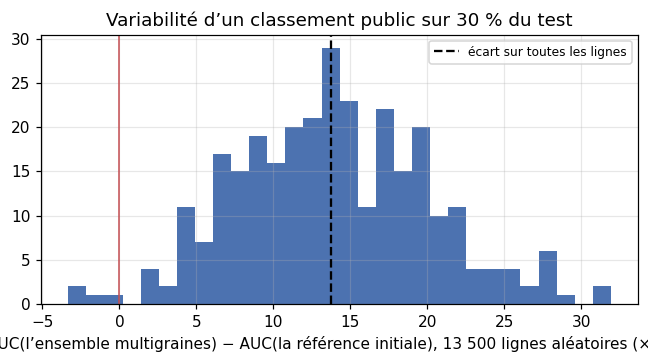

,"Courbe d’apprentissage, 84 000 lignes",Modèle réduit en validation croisée,Écart
fold,,,
1,0.914297,0.914450,-0.000153
2,0.927419,0.927037,0.000382
3,0.920750,0.920750,0.000000
4,0.916294,0.916733,-0.000440
5,0.921569,0.921801,-0.000232


In [19]:
labels = reference['accepted'].to_numpy()
new, old = pool[ENSEMBLE_MULTISEED], pool[MODEL_INITIAL_POOL_LABEL]
rng = np.random.default_rng(SEED)
subset_auc, paired = [], []
for _ in range(300):
    idx = rng.choice(len(labels), 13500, replace=False)
    auc_new = roc_auc_score(labels[idx], new[idx])
    subset_auc.append(auc_new)
    paired.append(auc_new - roc_auc_score(labels[idx], old[idx]))
true_gap = roc_auc_score(labels, new) - roc_auc_score(labels, old)
print(f'Écart l’ensemble multigraines − la référence initiale sur les 105 000 lignes : {true_gap:+.5f}')
print(f'Sur 13 500 lignes aléatoires (≈ classement public) : écart-type AUC {np.std(subset_auc):.4f} ; écart-type de la différence appariée {np.std(paired):.4f} ; '
      f'fréquence d’inversion dans la simulation {np.mean(np.array(paired) < 0):.0%}')
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(np.array(paired) * 1e4, bins=30, color='#4c72b0')
ax.axvline(true_gap * 1e4, color='black', ls='--', label='écart sur toutes les lignes')
ax.axvline(0, color='#c44e52', lw=1)
ax.set_xlabel('AUC(l’ensemble multigraines) − AUC(la référence initiale), 13 500 lignes aléatoires (×1e-4)')
ax.set_title('Variabilité d’un classement public sur 30 % du test')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

lc = load_runs(FULL_DIR, LEARNING_CURVE_FULL_PATTERN).set_index('fold')['valid_auc']
reduced_model_runs = load_runs(CV_DIR, REDUCED_MODEL_RUN_PATTERN).set_index('fold')['valid_auc']
display_named(pd.DataFrame({'Courbe d’apprentissage, 84 000 lignes': lc, 'Modèle réduit en validation croisée': reduced_model_runs, 'Écart': lc - reduced_model_runs}).round(6))

D'un tirage à l'autre, l'AUC d'une soumission varie d'environ 0.004 (écart-type), mais la différence entre l'ensemble final et la référence varie seulement de 0.0006. Avec un écart de 0.0014, l'ordre s'inverse dans 1 % des tirages environ ; avec 0.0005, dans 20 %. Entre deux sessions Colab, l'écart par pli va de 0 à 0.0004. C'est pour cela que le critère des dernières expériences est de 0.0005.

## 6. Bilan

- Aucun contrôle ne justifiait de supprimer des lignes. Le gain des variables vient surtout du LTV.
- Ni les résidus par groupe, ni les autres modèles, ni les modes de calcul, ni les mélanges, ni les pseudo-étiquettes n'ont apporté de gain assez régulier.
- Ce qui aide, c'est davantage de données étiquetées : d'où le réentraînement sur les 105 000 lignes.

Nous n'utilisons pas les données HMDA publiques : le test en vient, et les rapprocher reviendrait à récupérer ses cibles.